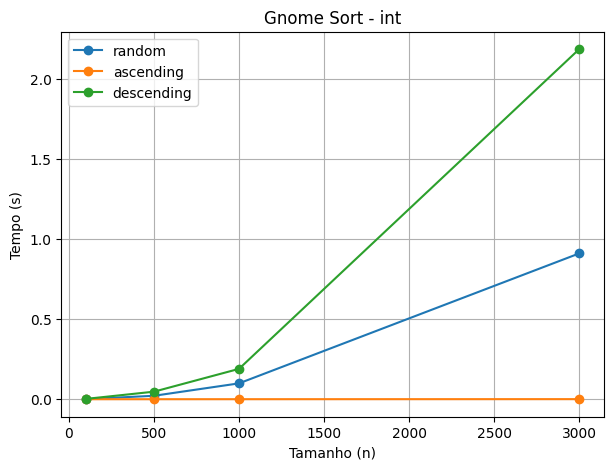

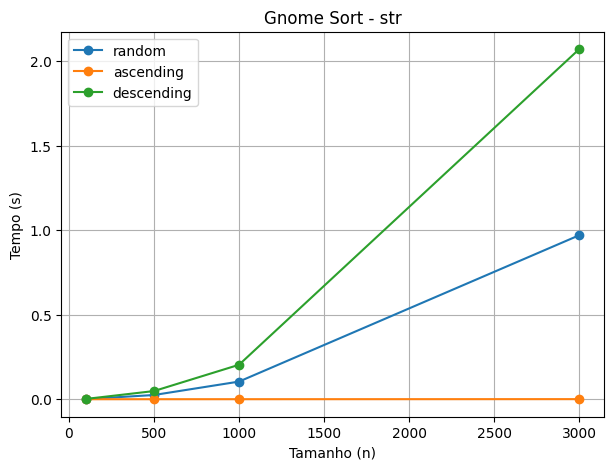

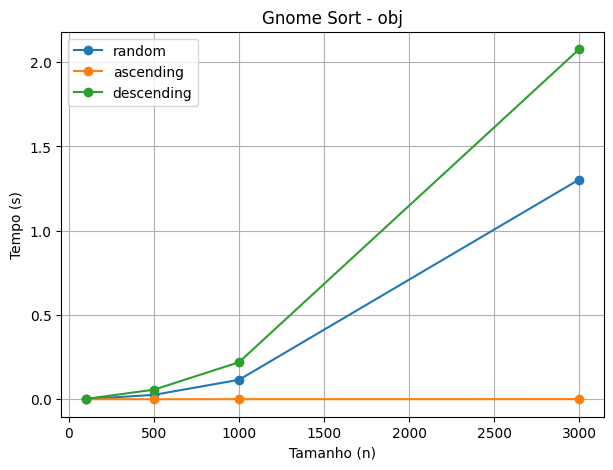

In [ ]:
import time
import random
import string
import matplotlib.pyplot as plt


# GNOME SORT (ALG PRINCIPAL)

def gnome_sort(arr, key=None, reverse=False):
    a = list(arr)
    n = len(a)
    pos = 0
    if key is None:
        def keyf(x): return x
    else:
        keyf = key
    while pos < n:
        if pos == 0:
            pos += 1
        else:
            if (keyf(a[pos]) >= keyf(a[pos-1])) ^ reverse:
                pos += 1
            else:
                a[pos], a[pos-1] = a[pos-1], a[pos]
                pos -= 1
    return a


# Função para medir tempo

def measure(arr, key=None, reverse=False, reps=3):
    times = []
    for _ in range(reps):
        start = time.perf_counter()
        gnome_sort(arr, key=key, reverse=reverse)
        times.append(time.perf_counter() - start)
    return sum(times)/len(times)

# definir os tamanhos e os tipos (colocar menor q 10k, senão demora muito)

sizes = [100, 500, 1000, 3000]
orders = ["random", "ascending", "descending"]

results = {"int": [], "str": [], "obj": []}


# parte para rodar os experimentos (orders não funcionaram em portugues)

for n in sizes:

    # por inteiros
    base = list(range(n))
    for order in orders:
        if order == "random":
            arr = random.sample(base, n)
        elif order == "ascending":
            arr = base
        else:
            arr = list(reversed(base))

        t = measure(arr)
        results["int"].append((n, order, t))

    # por strings
    base = [''.join(random.choices(string.ascii_letters, k=5)) for _ in range(n)]
    asc = sorted(base)
    desc = list(reversed(asc))

    for order, arr in [("random", base), ("ascending", asc), ("descending", desc)]:
        t = measure(arr)
        results["str"].append((n, order, t))

    # por objetos
    base = [{"key": x} for x in range(n)]
    for order in orders:
        if order == "random":
            arr = random.sample(base, n)
        elif order == "ascending":
            arr = base
        else:
            arr = list(reversed(base))

        t = measure(arr, key=lambda o: o["key"])
        results["obj"].append((n, order, t))


# Gerar e exibir os graficos

for dtype in results:
    plt.figure(figsize=(7,5))

    for order in orders:
        xs = [n for n,o,t in results[dtype] if o == order]
        ys = [t for n,o,t in results[dtype] if o == order]
        plt.plot(xs, ys, marker="o", label=order)

    plt.xlabel("Tamanho (n)")
    plt.ylabel("Tempo (s)")
    plt.title(f"Gnome Sort - {dtype}")
    plt.legend()
    plt.grid(True)
    plt.show()
